In [1]:
#import required packages and classes
import pandas as pd 
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import normalized_mutual_info_score
import seaborn as sns
import matplotlib.pyplot as plt 
import timeit
import warnings
warnings.filterwarnings('ignore')

In [2]:
#defining function to calculate NMI scores using Kmeans clustreing with occupational ONET data and job task description data
def kmeanCluster(job_codes, data, labels):
    kmeans = KMeans(n_clusters=22, random_state=0)
    kmeans.fit(job_codes)
    true_pred = kmeans.labels_
    kmeans = KMeans(n_clusters=22, random_state=0)
    kmeans.fit(data)
    y_pred = kmeans.labels_
    nmi_score = labels - normalized_mutual_info_score(true_pred, y_pred)
    return nmi_score

In [3]:
#function to calculate cosine similarity
def cosine(vec1, vec2):
    dot_product = np.dot(vec1, vec2)
    norm_vec1 = np.linalg.norm(vec1)
    norm_vec2 = np.linalg.norm(vec2)    
    if norm_vec1 == 0 or norm_vec2 == 0:
        return 0  
    return dot_product / (norm_vec1 * norm_vec2)

In [4]:
#loading and displayig ONET occupational data
onet_data = pd.read_csv("Dataset/Occupation Data.txt", sep="\t")
onet_data

,O*NET-SOC Code,Title,Description
0,11-1011.00,Chief Executives,Determine and formulate policies and provide o...
1,11-1011.03,Chief Sustainability Officers,"Communicate and coordinate with management, sh..."
2,11-1021.00,General and Operations Managers,"Plan, direct, or coordinate the operations of ..."
3,11-1031.00,Legislators,"Develop, introduce, or enact laws and statutes..."
4,11-2011.00,Advertising and Promotions Managers,"Plan, direct, or coordinate advertising polici..."
...,...,...,...
1011,55-3014.00,Artillery and Missile Crew Members,"Target, fire, and maintain weapons used to des..."
1012,55-3015.00,Command and Control Center Specialists,"Operate and monitor communications, detection,..."
1013,55-3016.00,Infantry,Operate weapons and equipment in ground combat...
1014,55-3018.00,Special Forces,"Implement unconventional operations by air, la..."


In [5]:
#loading and displayig patent job description dataset
patent_data = pd.read_csv("Dataset/Task Statements.txt", usecols=['O*NET-SOC Code', 'Task'], sep="\t")
patent_data

,O*NET-SOC Code,Task
0,11-1011.00,Direct or coordinate an organization's financi...
1,11-1011.00,"Confer with board members, organization offici..."
2,11-1011.00,"Prepare budgets for approval, including those ..."
3,11-1011.00,"Direct, plan, or implement policies, objective..."
4,11-1011.00,Prepare or present reports concerning activiti...
...,...,...
18791,53-7121.00,Unload cars containing liquids by connecting h...
18792,53-7121.00,"Clean interiors of tank cars or tank trucks, u..."
18793,53-7121.00,Lower gauge rods into tanks or read meters to ...
18794,53-7121.00,Operate conveyors and equipment to transfer gr...


In [6]:
#loading & displaying link-embed-mistral embedding values
job_embed = np.load("model/job_link_embed_mistral.npy")
task_embed = np.load("model/task_link_mistral.npy")
print("Embedding Values = "+str(job_embed))

Embedding Values = [[-7.54782564e-01 -2.98963609e-01  2.43326883e-01 ...  1.20657959e-02
  -6.70321993e-04 -1.94393378e-02]
 [-6.90601115e-01 -1.75852898e-01  2.48057399e-01 ...  3.49376618e-02
  -2.09625971e-02 -4.54189603e-02]
 [-7.48547502e-01 -3.08059193e-01  1.34044105e-01 ...  8.47869339e-03
  -7.67119878e-03 -2.18023544e-02]
 ...
 [-6.43798431e-01 -3.06138571e-01  2.61722211e-01 ...  2.86557165e-02
  -2.86557165e-03 -2.19693827e-02]
 [-7.19420036e-01 -2.70652780e-01  1.48815516e-01 ... -2.61079852e-03
   1.16035490e-03 -4.93150831e-03]
 [-4.87446138e-01 -3.84107557e-01  2.84668545e-01 ... -1.36484919e-02
   5.84935366e-02 -2.72969837e-02]]


In [7]:
#calculating NMI scores of both job and task description data
onet_data['O*NET-SOC Code'] = onet_data['O*NET-SOC Code'].astype('category')#converting job soc code to numeric values
onet_data['O*NET-SOC Code'] = onet_data['O*NET-SOC Code'].cat.codes
patent_data['O*NET-SOC Code'] = patent_data['O*NET-SOC Code'].astype('category')
patent_data['O*NET-SOC Code'] = patent_data['O*NET-SOC Code'].cat.codes
job_codes = onet_data.values
job_codes = job_codes[:,0:1].astype('int')
job_nmi_score = kmeanCluster(job_codes, job_embed, 1)#clustering job data
job_codes = patent_data.values
job_codes = job_codes[:,0:1].astype('int')
task_nmi_score = kmeanCluster(job_codes, task_embed, 0.7)#clustering task data
print("Link Emded Mistral Job Description NMI  = "+str(job_nmi_score))
print("Link Emded Mistral Task Description NMI = "+str(task_nmi_score))

Link Emded Mistral Job Description NMI  = 0.6908589027761425
Link Emded Mistral Task Description NMI = 0.5937274328607888


In [9]:
#function to identify top 20 job task demand
task_names = patent_data['Task'].ravel() 
top_20_job_task = {}
for i in range(len(task_embed)):#looping all task embedding
    query = task_embed[i]
    for j in range(0, 100):
        if i != j:
            value = task_embed[j]
            similarity = cosine(query, value)#calculating cosine similarity between cureent and other job task
            if similarity > 0:
                if task_names[i] in top_20_job_task:
                    top_20_job_task[task_names[i]] += 1
                else:
                    top_20_job_task[task_names[i]] = 1
sorted_task = sorted(top_20_job_task.items(), key=lambda item: item[1], reverse=True)
sorted_task = sorted_task[0:20]
sorted_task = pd.DataFrame(sorted_task, columns=['Task', 'Demand'])
print("Top 20 Highest Job Task Demand")
sorted_task                    

Top 20 Highest Job Task Demand


,Task,Demand
0,"Maintain student attendance records, grades, a...",3400
1,Maintain regularly scheduled office hours to a...,3400
2,Serve on academic or administrative committees...,3400
3,Compile bibliographies of specialized material...,3400
4,"Participate in student recruitment, registrati...",3400
5,Act as advisers to student organizations.,3400
6,"Initiate, facilitate, and moderate classroom d...",3300
7,"Compile, administer, and grade examinations, o...",3300
8,Collaborate with colleagues to address teachin...,3300
9,"Supervise undergraduate or graduate teaching, ...",3300


In [11]:
#analysing top 20 lowest job task demand
lowest_task = sorted(top_20_job_task.items(), key=lambda item: item[1], reverse=False)
lowest_task = lowest_task[0:20]
lowest_task = pd.DataFrame(lowest_task, columns=['Task', 'Demand'])
print("Top 20 Lowest Job Task Demand")
lowest_task

Top 20 Lowest Job Task Demand


,Task,Demand
0,Perform incisional biopsies to diagnose melanoma.,15
1,Tow and maneuver barges or signal tugboats to ...,16
2,Negotiate labor disputes.,18
3,Diagnose or treat allergic or immunologic cond...,18
4,"Grill and garnish hamburgers or other meats, s...",18
5,Spray insecticides or fumigants to prevent ins...,19
6,Dig trenches.,22
7,Guard lodging of sequestered jury.,23
8,"Perform abdominal, pelvic, or retroperitoneal ...",24
9,Rewrap soiled or broken parcels.,24


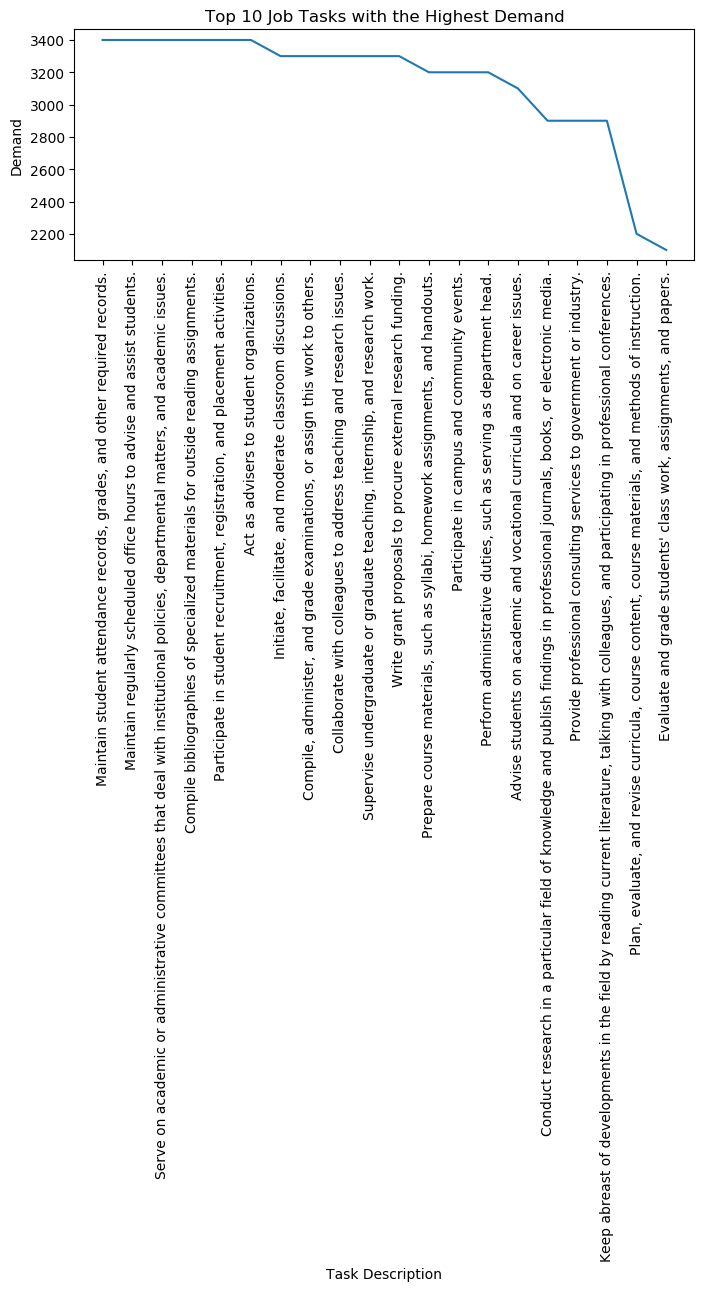

In [12]:
#visualizing top 20 job task demand
plt.figure(figsize=(8, 3))
sns.lineplot(x=sorted_task['Task'], y=sorted_task['Demand'])
plt.title("Top 10 Job Tasks with the Highest Demand")
plt.xlabel("Task Description")
plt.ylabel("Demand")
plt.xticks(rotation=90)
plt.show()

In [14]:
#analysing top 20 job titles in demand
dataset = pd.read_csv("Dataset/dataset.csv")
job_name = dataset['Title']
top_20_jobs = {}
for i in range(len(task_embed)):
    query = task_embed[i]
    for j in range(0, 100):
        if i != j:
            value = task_embed[j]
            similarity = cosine(query, value)
            if similarity > 0:
                if job_name[i] in top_20_jobs:
                    top_20_jobs[job_name[i]] += 1
                else:
                    top_20_jobs[job_name[i]] = 1
sorted_job = sorted(top_20_jobs.items(), key=lambda item: item[1], reverse=True)
sorted_job = sorted_job[0:20]
sorted_job = pd.DataFrame(sorted_job, columns=['Job', 'Demand'])
print("Top 20 Highest Job Demand")
sorted_job   

Top 20 Highest Job Demand


,Job,Demand
0,"Special Education Teachers, Middle School",4000
1,"Special Education Teachers, Secondary School",4000
2,Telecommunications Equipment Installers and Re...,3900
3,Industrial Ecologists,3800
4,"Elementary School Teachers, Except Special Edu...",3800
5,Aircraft Mechanics and Service Technicians,3800
6,"Kindergarten Teachers, Except Special Education",3700
7,"Adult Basic Education, Adult Secondary Educati...",3700
8,Search Marketing Strategists,3600
9,"Special Education Teachers, Preschool",3600


In [15]:
#identifying top 20 lowest demands
lowest_job = sorted(top_20_jobs.items(), key=lambda item: item[1], reverse=False)
lowest_job = lowest_job[0:20]
lowest_job = pd.DataFrame(lowest_job, columns=['Job', 'Demand'])
print("Top 20 Lowest Jobs Demand")
lowest_job

Top 20 Lowest Jobs Demand


,Job,Demand
0,Shampooers,400
1,"Graders and Sorters, Agricultural Products",500
2,Pile Driver Operators,500
3,Aircraft Cargo Handling Supervisors,600
4,Dredge Operators,600
5,Floor Sanders and Finishers,644
6,"Insurance Appraisers, Auto Damage",700
7,Farm Labor Contractors,700
8,Insurance Underwriters,700
9,Reinforcing Iron and Rebar Workers,700


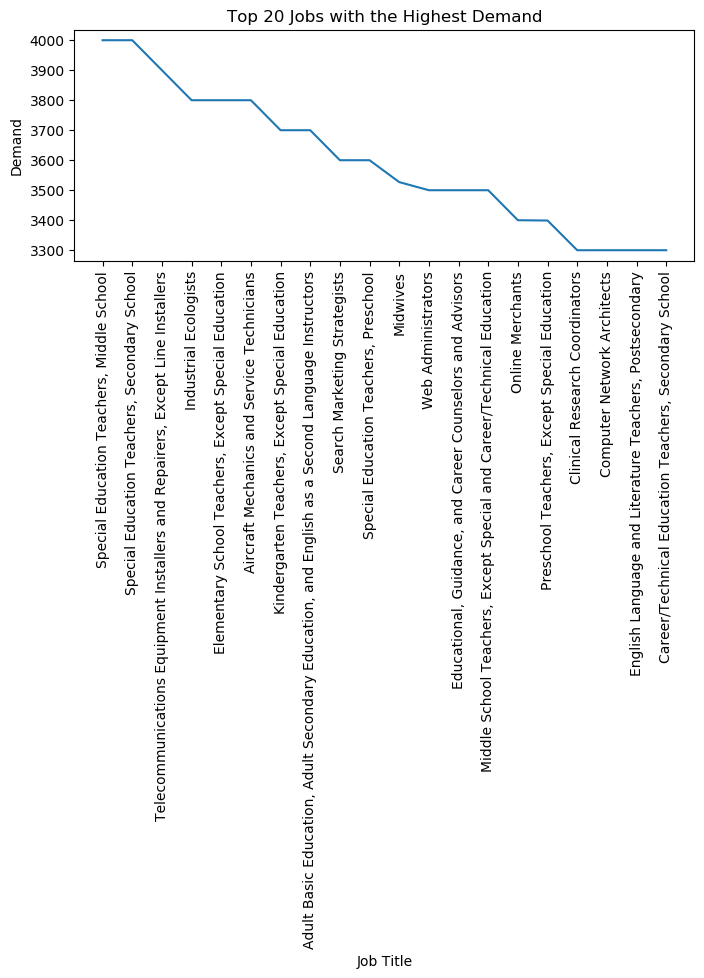

In [16]:
#visuaizing top 20 jobs in demands
plt.figure(figsize=(8, 3))
sns.lineplot(x=sorted_job['Job'], y=sorted_job['Demand'])
plt.title("Top 20 Jobs with the Highest Demand")
plt.xlabel("Job Title")
plt.ylabel("Demand")
plt.xticks(rotation=90)
plt.show()

In [24]:
#extension manhattan function to calculate similarity efficiently
def manhattan_similarity(vec1, vec2):
    return sum(abs(v1 - v2) for v1, v2 in zip(vec1, vec2))

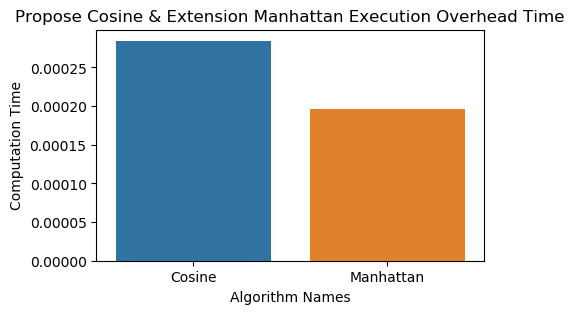

In [27]:
#compare computation performnace of propose Cosine and Manhattan distnace
start = timeit.default_timer()
cosine_score = cosine(task_embed[0], task_embed[1])#executing cosine
end = timeit.default_timer()
cosine_time = end - start #calculating cosine computation overhead 
start = timeit.default_timer()
manhattan_score = manhattan_similarity(task_embed[0], task_embed[1])#executing jaccard
end = timeit.default_timer()
manhattan_time = end - start #calculating extension manhattan computation overhead 
#visualizing propose and extension computation graph
plt.figure(figsize = (5, 3)) 
sns.barplot(x=['Cosine', 'Manhattan'], y=[cosine_time, manhattan_time])
plt.title("Propose Cosine & Extension Manhattan Execution Overhead Time")
plt.ylabel("Computation Time")
plt.xlabel("Algorithm Names")
plt.show()

In [30]:
#loading test task description and predict suitable job for that task description using cosine similarity 
testData = pd.read_csv("Dataset/testData.csv")
task = testData['task']
index = testData['index']
output = []
for i in range(len(index)):#loop all test description index
    similarity_score = 1000000
    match_job = ""
    for j in range(len(task_embed)):#loop all job task description 
        if j != index[i]:
            similarity = manhattan_similarity(task_embed[j], task_embed[index[i]])#use extension similarity to find similarity
            if similarity < similarity_score:#take job with highest similarity
                similarity_score = similarity
                match_job = job_name[j]
    output.append([task[i], match_job, similarity_score])#print predicted job along with task details and cosine similarity
output = pd.DataFrame(output, columns=['Task Description', 'Suitable Job', 'Manhattan Similarity Score'])
output

,Task Description,Suitable Job,Manhattan Similarity Score
0,"Prepare bylaws approved by elected officials, ...","Farmers, Ranchers, and Other Agricultural Mana...",5.649689
1,Review reports of securities transactions or p...,First-Line Supervisors of Retail Sales Workers,3.285954
2,Coordinate or recommend procedures for facilit...,Mechanical Engineers,3.058195
3,"Provide food, drinking water, and field sanita...",First-Line Supervisors of Food Preparation and...,4.278425
4,Plan and implement laboratory operations to de...,Manufacturing Engineers,3.350958
5,Collect cards or tickets from players.,Tour Guides and Escorts,3.328583
6,"Dispense medical devices or drugs, and calcula...",Radiologists,4.326370
7,"Review taxpayer accounts, and conduct audits o...","Title Examiners, Abstractors, and Searchers",4.568922
8,"Supervise pest or weed control operations, inc...",Soil and Plant Scientists,3.662586
9,"Design, or supervise the design of, systems, p...","Mining and Geological Engineers, Including Min...",2.826811
